# 02: Airport Graph Construction and Data Quality

## Question: What counts as an airport and a connection?

This notebook builds an airport graph directly from the local OpenFlights route and airport files. Its purpose is to explain and test the modeling choices before the rest of the group measures graph structure. Run every cell in order from the project directory using the jupyter kernel with pandas, NetworkX and Matplotlib installed.

### From the tutorial to this analysis

| Concept | Application here |
|---|---|
| Vertices, directed/undirected edges, simple graphs and multigraphs | An airport ID is a vertex; a listed route is initially an ordered record. Multiple records may describe the same airport pair. |
| Adjacency, degree, loops and the handshaking theorem | Adjacent airports share an edge; we remove self-loops and verify the resulting undirected degree sum. |
| Adjacency matrix and induced subgraphs | A small real-airport neighborhood is displayed as both a graph and a symmetric matrix. |
| Edge weights as path costs | A route-record count is not flight frequency and is not automatically a valid shortest-path cost. |

[OpenFlights data documentation](https://openflights.org/data.php). The local data is a static snapshot; its exact date is not established here.

## Model contract

- **Airport / vertex:** an integer OpenFlights airport ID that matches a unique row in `airports.dat` and occurs at an endpoint of a retained route. IATA/ICAO codes and names are labels, not graph keys.
- **Retained route record:** both airport IDs are valid and present in the airport catalog, the number of intermediate stops is known to be zero, and the endpoints are different. Missing/unmatched IDs, nonzero or unknown stops, and self-loops are reported and excluded. Codeshares are included; code/catalog mismatches are reported, not automatically remapped.
- **Connection / edge:** one unweighted undirected edge $\{u,v\}$ if at least one retained record lists $u\to v$ or $v\to u$. Duplicate, reverse, and multi-airline records can produce the same edge. An edge does **not** prove reverse-direction service.
- **Scope:** only airports incident to retained route records are included; catalog-only airports are not automatically isolated in the real aviation system. Degree-one airports remain. No flight frequency, passenger volume, current schedule, journey time, or operational resilience is inferred.

For example, A→B from two airlines and B→A from one airline are three route records, two ordered airport pairs and one undirected binary edge. The analysis below checks these distinctions using actual data, not just this illustration.

### The model in everyday language

- **Airport ID versus code:** the ID is the key identifying an airport; its name and codes are labels attached to that key. Airport ID **1**, for example, has the code **GKA** (Goroka). Matching a code is not a substitute for the documented ID rule.
- **Simple graph:** at most one line joins two different airports, regardless of how many listings connect them; there are no lines from an airport to itself.
- **Multigraph and multiplicity:** several lines may join the same airports. Three distinct listings between A and B give listing multiplicity three. In a **directed** multigraph, arrows also preserve each listing's direction.
- **Self-loop:** A → A connects an airport to itself. We exclude it because our model studies connections between different airports.

**Audience question:** 
- If two airlines list A → B and another lists B → A, how many connections are in our model?
    - **One**—the three listings support one unordered airport pair.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
from IPython.display import display, FileLink

DATA_DIR = Path('../data')
ROUTE_FIELDS = ['airline', 'airline_id', 'source_code', 'source_id', 'destination_code',
                'destination_id', 'codeshare', 'stops', 'equipment']
AIRPORT_FIELDS = ['airport_id', 'name', 'city', 'country', 'iata', 'icao', 'latitude',
                  'longitude', 'altitude', 'timezone', 'dst', 'timezone_name', 'type', 'source']

if not all((DATA_DIR / filename).is_file() for filename in ['routes.dat', 'airports.dat']):
    raise FileNotFoundError('Run from the project directory containing data/routes.dat and data/airports.dat.')

routes_raw = pd.read_csv(DATA_DIR / 'routes.dat', header=None, names=ROUTE_FIELDS,
                         dtype='string', keep_default_na=False)
airports_raw = pd.read_csv(DATA_DIR / 'airports.dat', header=None, names=AIRPORT_FIELDS,
                           dtype='string', keep_default_na=False)
routes = routes_raw.copy()
airports = airports_raw.copy()
for frame in (routes, airports):
    for field in frame.columns:
        frame[field] = frame[field].str.strip().replace({'': pd.NA, r'\N': pd.NA})

print(f'Loaded {len(routes):,} route records and {len(airports):,} airport records.')
display(routes.head(10))
display(airports[['airport_id', 'name', 'iata', 'icao']].head(10))

Loaded 67,663 route records and 7,698 airport records.


,airline,airline_id,source_code,source_id,destination_code,destination_id,codeshare,stops,equipment
0,2B,410,AER,2965,KZN,2990,<NA>,0,CR2
1,2B,410,ASF,2966,KZN,2990,<NA>,0,CR2
2,2B,410,ASF,2966,MRV,2962,<NA>,0,CR2
3,2B,410,CEK,2968,KZN,2990,<NA>,0,CR2
4,2B,410,CEK,2968,OVB,4078,<NA>,0,CR2
5,2B,410,DME,4029,KZN,2990,<NA>,0,CR2
6,2B,410,DME,4029,NBC,6969,<NA>,0,CR2
7,2B,410,DME,4029,TGK,<NA>,<NA>,0,CR2
8,2B,410,DME,4029,UUA,6160,<NA>,0,CR2
9,2B,410,EGO,6156,KGD,2952,<NA>,0,CR2


,airport_id,name,iata,icao
0,1,Goroka Airport,GKA,AYGA
1,2,Madang Airport,MAG,AYMD
2,3,Mount Hagen Kagamuga Airport,HGU,AYMH
3,4,Nadzab Airport,LAE,AYNZ
4,5,Port Moresby Jacksons International Airport,POM,AYPY
5,6,Wewak International Airport,WWK,AYWK
6,7,Narsarsuaq Airport,UAK,BGBW
7,8,Godthaab / Nuuk Airport,GOH,BGGH
8,9,Kangerlussuaq Airport,SFJ,BGSF
9,10,Thule Air Base,THU,BGTL


## 1. Audit airport identity and route records

The CSV input has no headers. The loader keeps text intact, then converts blanks and literal `\N` to missing values. We parse IDs as nonnegative integers and check the catalog for missing or duplicate IDs before matching routes. Code comparisons accept the catalog's IATA **or** ICAO code; a mismatch is a warning, not proof of which value is correct.

The counts below are **overlapping diagnostics**: one record may have several issues, so do not sum them to obtain an exclusion total. Exact duplicates compare all nine fields; a repeated directed pair can instead be a different airline, codeshare, or equipment listing.

**Duplicate does not mean “same airport pair.”** Two identical nine-field rows repeat the same information. Two rows for different airlines can describe A → B without being identical. A reverse listing B → A is another ordered pair; it becomes the same edge only after we discard direction.

**Reading the audit:** one record can have both a source issue and a destination issue. Counting both flags does not mean two records were removed. The sequential exclusion table below assigns each excluded record exactly one reason.

In [2]:
def parse_airport_ids(values):
    digits = values.where(values.str.fullmatch(r'[0-9]+', na=False))
    return pd.to_numeric(digits, errors='coerce').astype('Int64')

for field in ['source_code', 'destination_code']:
    routes[field] = routes[field].str.upper()
for field in ['iata', 'icao']:
    airports[field] = airports[field].str.upper()
for field in ['source_id', 'destination_id']:
    routes[field] = parse_airport_ids(routes[field])
airports['airport_id'] = parse_airport_ids(airports['airport_id'])
routes['stop_count'] = pd.to_numeric(routes['stops'], errors='coerce')
if airports['airport_id'].isna().any() or airports['airport_id'].duplicated().any():
    raise ValueError('The airport catalog must have valid, unique airport IDs.')
catalog = airports.set_index('airport_id')

endpoint_diagnostics = {}
endpoint_mismatches = {}
for endpoint in ['source', 'destination']:
    airport_ids = routes[f'{endpoint}_id']
    codes = routes[f'{endpoint}_code']
    catalog_found = airport_ids.isin(catalog.index)
    expected_iata = airport_ids.map(catalog['iata'])
    expected_icao = airport_ids.map(catalog['icao'])
    code_matches = codes.eq(expected_iata).fillna(False) | codes.eq(expected_icao).fillna(False)
    mismatch = catalog_found & codes.notna() & ~code_matches
    endpoint_mismatches[endpoint] = mismatch
    endpoint_diagnostics[endpoint] = {
        'Missing or invalid airport ID': int(airport_ids.isna().sum()),
        'Present ID absent from catalog': int((airport_ids.notna() & ~catalog_found).sum()),
        'Missing airport code': int(codes.isna().sum()),
        'Code differs from both catalog codes': int(mismatch.sum()),
    }
display(pd.DataFrame(endpoint_diagnostics))

quality_summary = {
    'Exact raw duplicate records after the first': int(routes_raw.duplicated().sum()),
    'Normalized duplicate records after the first': int(routes[ROUTE_FIELDS].duplicated().sum()),
    'Records marked codeshare': int(routes['codeshare'].eq('Y').fillna(False).sum()),
    'Records with nonzero stops': int((routes['stop_count'].notna() & routes['stop_count'].ne(0)).sum()),
    'Records with missing or invalid stops': int(routes['stop_count'].isna().sum()),
    'Records with matching endpoint IDs (loops)': int((routes['source_id'].notna() & routes['source_id'].eq(routes['destination_id']).fillna(False)).sum()),
}
for field in ['iata', 'icao']:
    available_codes = airports[field].dropna()
    quality_summary[f'Catalog {field.upper()} codes repeated across rows'] = int(available_codes[available_codes.duplicated(keep=False)].nunique())
display(pd.Series(quality_summary, name='records or distinct codes').to_frame())

for endpoint in ['source', 'destination']:
    examples = routes.loc[endpoint_mismatches[endpoint], [f'{endpoint}_id', f'{endpoint}_code']].head(10).copy()
    examples['catalog_iata'] = examples[f'{endpoint}_id'].map(catalog['iata'])
    examples['catalog_icao'] = examples[f'{endpoint}_id'].map(catalog['icao'])
    print(f'{endpoint.title()} endpoint: examples of code/ID inconsistencies')
    display(examples)

,source,destination
Missing or invalid airport ID,220,221
Present ID absent from catalog,263,267
Missing airport code,0,0
Code differs from both catalog codes,538,543


,records or distinct codes
Exact raw duplicate records after the first,0
Normalized duplicate records after the first,0
Records marked codeshare,14597
Records with nonzero stops,11
Records with missing or invalid stops,0
Records with matching endpoint IDs (loops),1
Catalog IATA codes repeated across rows,0
Catalog ICAO codes repeated across rows,0


Source endpoint: examples of code/ID inconsistencies


,source_id,source_code,catalog_iata,catalog_icao
183,2400,CGY,<NA>,RPML
773,4085,INC,<NA>,ZLIC
774,4085,INC,<NA>,ZLIC
775,4085,INC,<NA>,ZLIC
776,4085,INC,<NA>,ZLIC
1202,2223,ISB,<NA>,OPRN
1203,2223,ISB,<NA>,OPRN
1779,5844,TNO,<NA>,MRCV
1780,5844,TNO,<NA>,MRCV
1843,2400,CGY,<NA>,RPML


Destination endpoint: examples of code/ID inconsistencies


,destination_id,destination_code,catalog_iata,catalog_icao
193,2400,CGY,<NA>,RPML
629,4085,INC,<NA>,ZLIC
677,4085,INC,<NA>,ZLIC
761,4085,INC,<NA>,ZLIC
816,4085,INC,<NA>,ZLIC
1200,2223,ISB,<NA>,OPRN
1207,2223,ISB,<NA>,OPRN
1761,5844,TNO,<NA>,MRCV
1774,5844,TNO,<NA>,MRCV
1805,2400,CGY,<NA>,RPML


In [3]:
decision_examples = []
for label, mask, decision, reason in [
    ('Missing / invalid ID', routes['source_id'].isna() | routes['destination_id'].isna(), 'Exclude', 'Cannot identify both endpoints'),
    ('ID absent from catalog', routes['source_id'].notna() & ~routes['source_id'].isin(catalog.index), 'Exclude', 'Cannot match this endpoint to the catalog'),
    ('Code disagrees', endpoint_mismatches['source'], 'Flag; retain if other checks pass', 'Catalog-matched ID is the chosen key'),
    ('Self-loop', routes['source_id'].notna() & routes['source_id'].eq(routes['destination_id']).fillna(False), 'Exclude', 'Model connects different airports'),
]:
    sample = routes.loc[mask].head(1)
    if not sample.empty:
        r = sample.iloc[0]
        decision_examples.append({'Issue': label, 'Example (code / ID)': f"{r.source_code} / {r.source_id} → {r.destination_code} / {r.destination_id}", 'Decision': decision, 'Reason': reason})
display(pd.DataFrame(decision_examples))

,Issue,Example (code / ID),Decision,Reason
0,Missing / invalid ID,DME / 4029 → TGK / <NA>,Exclude,Cannot identify both endpoints
1,ID absent from catalog,AOS / 7167 → KZB / 7176,Exclude,Cannot match this endpoint to the catalog
2,Code disagrees,CGY / 2400 → MNL / 2397,Flag; retain if other checks pass,Catalog-matched ID is the chosen key
3,Self-loop,PKN / 3910 → PKN / 3910,Exclude,Model connects different airports


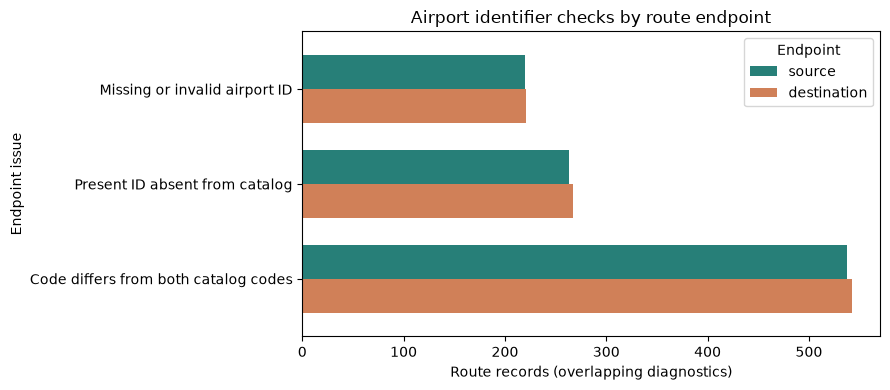

In [4]:
audit_chart = pd.DataFrame(endpoint_diagnostics).loc[
    ['Missing or invalid airport ID', 'Present ID absent from catalog',
     'Code differs from both catalog codes']
]
axis = audit_chart.plot.barh(figsize=(9, 4), color=['#277f78', '#d08058'], width=0.72)
axis.set_xlabel('Route records (overlapping diagnostics)')
axis.set_ylabel('Endpoint issue')
axis.set_title('Airport identifier checks by route endpoint')
axis.legend(title='Endpoint')
axis.invert_yaxis()
plt.tight_layout()
plt.show()

## 2. Construct and validate the shared simple graph

For each input row, apply the checks in the order shown. A row is counted at its **first** failed check; unlike the diagnostic table, the exclusions are mutually exclusive and reconcile to the total. No record is removed merely because it is a codeshare or has a code/catalog mismatch.

For retained rows, sort the two IDs to obtain a canonical unordered pair. The set of these pairs becomes $E$; their endpoint IDs become $V$. This makes graph topology independent of input row order. The graph deliberately has no edge `weight` attribute. NetworkX can store loops in `Graph`, so we check that our resulting graph is actually simple.

**Why check the degree sum?** The degree of an airport is its number of distinct neighbors. Each connection touches two airports, so adding all degrees counts every edge twice (the **handshaking theorem**). In A–B–C the degrees are 1, 2 and 1: their sum is 4, twice the two edges. This is a consistency check, not a measure of flight traffic.

In [5]:
def filter_route_records(route_table, catalog_ids):
    checks = [
        ('Missing or invalid endpoint ID', route_table['source_id'].notna() & route_table['destination_id'].notna()),
        ('Endpoint ID absent from catalog', route_table['source_id'].isin(catalog_ids) & route_table['destination_id'].isin(catalog_ids)),
        ('Nonzero or unknown stop count', route_table['stop_count'].eq(0).fillna(False)),
        ('Same airport at both endpoints', route_table['source_id'].ne(route_table['destination_id']).fillna(False)),
    ]
    active = pd.Series(True, index=route_table.index)
    exclusions = {}
    for reason, passed in checks:
        passed = passed.fillna(False)
        exclusions[reason] = int((active & ~passed).sum())
        active &= passed
    return route_table.loc[active].copy(), exclusions


def unordered_pairs(route_table):
    return {tuple(sorted((int(source), int(destination))))
            for source, destination in route_table[['source_id', 'destination_id']].itertuples(index=False, name=None)}


retained, exclusions = filter_route_records(routes, catalog.index)
edge_pairs = unordered_pairs(retained)
shared_graph = nx.Graph()
shared_graph.add_edges_from(sorted(edge_pairs))
for airport_id in shared_graph.nodes:
    record = catalog.loc[airport_id]
    shared_graph.nodes[airport_id].update({field: None if pd.isna(record[field]) else str(record[field])
                                           for field in ['name', 'city', 'country', 'iata', 'icao']})
shared_graph.graph.update(node_key='OpenFlights airport ID', direction='undirected',
                          edge_rule='one or more retained zero-stop listings in either direction',
                          weights='none', codeshares='included')

attrition = pd.Series({'Input route records': len(routes),
                       **{f'Excluded: {reason}': count for reason, count in exclusions.items()},
                       'Retained route records': len(retained)}, name='records')
display(attrition.to_frame())
print(f'Graph: {shared_graph.number_of_nodes():,} airports; {shared_graph.number_of_edges():,} undirected connections.')
assert sum(exclusions.values()) + len(retained) == len(routes)
assert not shared_graph.is_directed() and not shared_graph.is_multigraph()
assert nx.number_of_selfloops(shared_graph) == 0
assert set(shared_graph.nodes).issubset(set(catalog.index))
assert shared_graph.number_of_edges() == len(edge_pairs)
assert sum(degree for _, degree in shared_graph.degree()) == 2 * shared_graph.number_of_edges()
assert edge_pairs == unordered_pairs(retained.sample(frac=1, random_state=42))

,records
Input route records,67663
Excluded: Missing or invalid endpoint ID,423
Excluded: Endpoint ID absent from catalog,469
Excluded: Nonzero or unknown stop count,11
Excluded: Same airport at both endpoints,1
Retained route records,66759


Graph: 3,214 airports; 18,858 undirected connections.


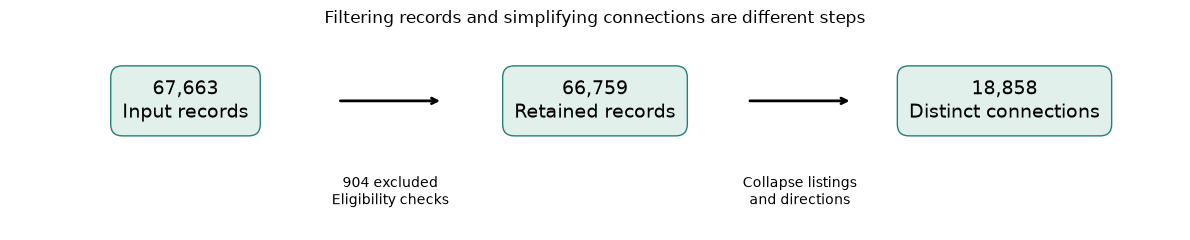

Collapsing multiple listings does not mean those listings were errors.


In [6]:
fig, ax = plt.subplots(figsize=(12, 2.5))
ax.axis('off')
for x, count, label in [(0.15, len(routes), 'Input records'), (0.5, len(retained), 'Retained records'), (0.85, len(edge_pairs), 'Distinct connections')]:
    ax.text(x, .65, f'{count:,}\n{label}', ha='center', va='center', fontsize=14,
            bbox=dict(boxstyle='round,pad=.6', facecolor='#e2f0ec', edgecolor='#277f78'), transform=ax.transAxes)
for start, end, label in [(.28, .37, f'{sum(exclusions.values()):,} excluded\nEligibility checks'), (.63, .72, 'Collapse listings\nand directions')]:
    ax.annotate('', xy=(end,.65), xytext=(start,.65), xycoords='axes fraction', arrowprops=dict(arrowstyle='->', lw=2))
    ax.text((start+end)/2,.13,label,ha='center',fontsize=10,transform=ax.transAxes)
ax.set_title('Filtering records and simplifying connections are different steps')
plt.tight_layout(); plt.show()
print('Collapsing multiple listings does not mean those listings were errors.')

## 3. Real route records: direction, duplicates and multiplicity

Tutorial 10.1 distinguishes ordered edges from unordered edges. We now compare three levels on the retained data:

1. A **route record** has nine fields. Exact normalized duplicates are removed only for the optional listing-count example; the binary graph already collapses duplicates regardless.
2. A **directed airport pair** $(u,v)$ records at least one retained listing from $u$ to $v$. Reciprocal means both ordered pairs occur in the data; it does not mean equal frequency or current service.
3. An **undirected edge** $\{u,v\}$ collapses both directions and all listings between those IDs into one connection.

The next cell selects a real reciprocal pair with multiple distinct listings, when available. It displays the records and compares a directed multigraph of those listings with the binary graph. One multiedge is a distinct normalized nine-field record, **not** an individual scheduled flight. Missing fields are preserved as missing in the comparison.

In [7]:
unique_listings = retained.drop_duplicates(subset=ROUTE_FIELDS).copy()
direction_count_series = unique_listings.groupby(['source_id', 'destination_id']).size()
direction_counts = {(int(source), int(destination)): int(count)
                    for (source, destination), count in direction_count_series.items()}
directed_pairs = set(direction_counts)
reciprocal_edges = {edge for edge in edge_pairs if edge in directed_pairs and edge[::-1] in directed_pairs}
one_direction_edges = edge_pairs - reciprocal_edges
repeated_directed_pairs = sum(count > 1 for count in direction_counts.values())
comparison = {
    'Retained route records': len(retained),
    'Distinct normalized nine-field listings': len(unique_listings),
    'Distinct ordered airport pairs': len(directed_pairs),
    'Ordered pairs with multiple distinct listings': repeated_directed_pairs,
    'Unordered pairs listed both ways': len(reciprocal_edges),
    'Unordered pairs listed in one direction only': len(one_direction_edges),
    'Binary undirected edges': shared_graph.number_of_edges(),
}
display(pd.Series(comparison, name='count').to_frame())
assert len(reciprocal_edges) + len(one_direction_edges) == shared_graph.number_of_edges()

candidate_pairs = [edge for edge in sorted(reciprocal_edges)
                   if 3 <= direction_counts[edge] + direction_counts[edge[::-1]] <= 5]
selected_pair = candidate_pairs[0] if candidate_pairs else (min(reciprocal_edges) if reciprocal_edges else None)
if selected_pair is None:
    print('No reciprocal pair is available in this snapshot.')
    pair_listings = unique_listings.iloc[0:0].copy()
else:
    airport_one, airport_two = selected_pair
    pair_mask = ((unique_listings['source_id'].eq(airport_one) & unique_listings['destination_id'].eq(airport_two)) |
                 (unique_listings['source_id'].eq(airport_two) & unique_listings['destination_id'].eq(airport_one)))
    pair_listings = unique_listings.loc[pair_mask].copy()
    print(f'Example airport IDs: {airport_one} and {airport_two}; distinct listings: {len(pair_listings)}')
    display(pair_listings[['airline', 'airline_id', 'source_code', 'source_id',
                           'destination_code', 'destination_id', 'codeshare', 'stops', 'equipment']])

,count
Retained route records,66759
Distinct normalized nine-field listings,66759
Distinct ordered airport pairs,36906
Ordered pairs with multiple distinct listings,16275
Unordered pairs listed both ways,18048
Unordered pairs listed in one direction only,810
Binary undirected edges,18858


Example airport IDs: 1 and 5; distinct listings: 4


,airline,airline_id,source_code,source_id,destination_code,destination_id,codeshare,stops,equipment
17315,CG,1308,GKA,1,POM,5,<NA>,0,DH8
17358,CG,1308,POM,5,GKA,1,<NA>,0,DH8
46428,PX,328,GKA,1,POM,5,<NA>,0,DH4 DH8 DH3
46469,PX,328,POM,5,GKA,1,<NA>,0,DH4 DH8 DH3


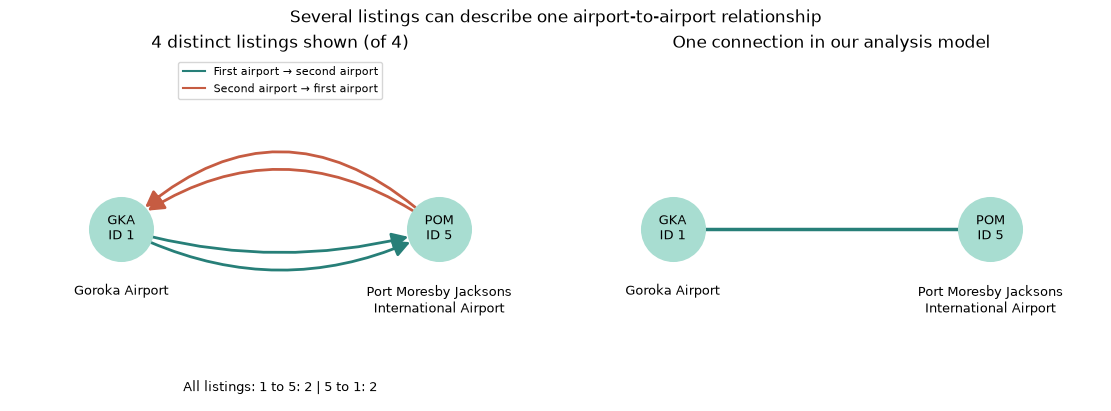

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
if selected_pair is None:
    for axis in axes:
        axis.text(0.5, 0.5, 'No reciprocal example available', ha='center', va='center', transform=axis.transAxes)
        axis.set_axis_off()
else:
    airport_one, airport_two = selected_pair
    example_positions = {airport_one: (0, 0), airport_two: (2, 0)}
    example_labels = {}
    for airport_id in selected_pair:
        attributes = shared_graph.nodes[airport_id]
        code = attributes.get('iata') or attributes.get('icao') or 'ID'
        example_labels[airport_id] = f"{code}\nID {airport_id}"
    shown_listings = pair_listings.head(8)
    listing_graph = nx.MultiDiGraph()
    listing_graph.add_nodes_from(selected_pair)
    for listing_number, record in enumerate(shown_listings.itertuples(index=False)):
        listing_graph.add_edge(int(record.source_id), int(record.destination_id), key=listing_number)
    binary_example = shared_graph.subgraph(selected_pair).copy()
    for axis, example_graph, title in zip(
        axes, [listing_graph, binary_example],
        [f'{len(shown_listings)} distinct listings shown (of {len(pair_listings)})', 'One connection in our analysis model']
    ):
        nx.draw_networkx_nodes(example_graph, example_positions, ax=axis, node_color='#a8ddd1', node_size=2100)
        nx.draw_networkx_labels(example_graph, example_positions, labels=example_labels, ax=axis, font_size=9)
        import textwrap
        for airport_id, (x, y) in example_positions.items():
            axis.text(x, y - .32, textwrap.fill(shared_graph.nodes[airport_id]['name'], width=23),
                      ha='center', va='top', fontsize=9)
        axis.set_xlim(-0.7, 2.7)
        axis.set_ylim(-1.0, 1.0)
        axis.set_title(title)
        axis.set_axis_off()
    for index, edge in enumerate(listing_graph.edges(keys=True)):
        edge_color = '#277f78' if edge[0] == airport_one else '#c65c42'
        nx.draw_networkx_edges(listing_graph, example_positions, ax=axes[0], edgelist=[edge],
                               arrows=True, arrowstyle='-|>', arrowsize=24, node_size=2100,
                               connectionstyle=f'arc3,rad={0.15 + 0.11 * index}',
                               edge_color=edge_color, width=2)
    axes[0].text(0.5, 0.02,
                 f'All listings: {airport_one} to {airport_two}: {direction_counts[selected_pair]} | '
                 f'{airport_two} to {airport_one}: {direction_counts[selected_pair[::-1]]}',
                 transform=axes[0].transAxes, ha='center', va='bottom', fontsize=9)
    nx.draw_networkx_edges(binary_example, example_positions, ax=axes[1], edge_color='#277f78', width=2.5)
    assert binary_example.number_of_edges() == 1
    from matplotlib.lines import Line2D
    axes[0].legend(handles=[Line2D([0], [0], color='#277f78', label='First airport → second airport'),
                            Line2D([0], [0], color='#c65c42', label='Second airport → first airport')],
                   loc='upper center', fontsize=8)
fig.suptitle('Several listings can describe one airport-to-airport relationship', fontsize=12)
plt.show()

### Weight recommendation

**Default:** use the binary, unweighted `shared_graph` for the group's connectivity questions. Every edge says only that at least one retained listing exists in either direction.

**Optional alternative:** count distinct normalized nine-field route records across both directions for each unordered pair. This `listing_count` can describe the number of records supporting an edge, but codeshares and multiple airlines may overlap. It is not a count of flights, passengers, seats, or flight frequency. Count after canonicalizing both endpoints; repeatedly assigning a directed count to the same undirected edge can overwrite an earlier value and make the result row-order dependent.

A numeric edge attribute is not universally meaningful as a weight. Many shortest-path algorithms treat larger weights as greater **cost**, while community algorithms may treat larger weights as stronger **connections**. Do not silently use `listing_count` as either. The optional graph below stores it under an explicit name rather than the conventional default `weight`.

**A small example of the wrong weight:** suppose A–B has ten listings, while A–C and C–B each have one. If listing counts are treated as travel costs, a shortest-path algorithm prefers A–C–B because 1 + 1 < 10. That does not establish that the two-hop journey is faster or better. Our binary graph gives each edge one hop; it does not assign travel costs.

A weight is simply a number attached to an edge with a stated meaning. “More supporting listings,” “more minutes,” and “stronger connection” are different meanings and cannot be substituted automatically.

In [9]:
from collections import Counter

def count_distinct_listings(route_table):
    unique_rows = route_table.drop_duplicates(subset=ROUTE_FIELDS)
    return Counter(tuple(sorted((int(source), int(destination))))
                   for source, destination in unique_rows[['source_id', 'destination_id']].itertuples(index=False, name=None))

listing_counts = count_distinct_listings(retained)
listing_graph_optional = shared_graph.copy()
nx.set_edge_attributes(listing_graph_optional, listing_counts, 'listing_count')
assert set(listing_counts) == edge_pairs
assert sum(listing_counts.values()) == len(unique_listings)
assert listing_counts == count_distinct_listings(retained.sample(frac=1, random_state=42))
assert all('weight' not in attributes for _, _, attributes in shared_graph.edges(data=True))
if selected_pair is not None:
    print('Example undirected pair:', selected_pair)
    print('Distinct route listings in both directions:', listing_graph_optional.edges[selected_pair]['listing_count'])
    print('Shared graph edge attributes:', shared_graph.edges[selected_pair])
    assert listing_graph_optional.edges[selected_pair]['listing_count'] == len(pair_listings)
print('The listing-count alternative is order-independent; the shared graph remains unweighted.')

Example undirected pair: (1, 5)
Distinct route listings in both directions: 4
Shared graph edge attributes: {}
The listing-count alternative is order-independent; the shared graph remains unweighted.


### Sensitivity to the code-mismatch policy

A code disagreement does not prove that the ID is wrong. As an alternative assumption, exclude every retained record flagged at either endpoint and rebuild the topology. Compare unique records, incident airports and unordered pairs; source and destination flags are combined before counting. An edge disappears only if no remaining listing supports it. This comparison shows sensitivity to a policy, not which policy is correct.

In [10]:
mismatch_mask = (endpoint_mismatches['source'] | endpoint_mismatches['destination']).loc[retained.index]
flagged_retained = retained.loc[mismatch_mask]
flagged_pairs = unordered_pairs(flagged_retained)
flagged_airports = set(flagged_retained['source_id']) | set(flagged_retained['destination_id'])
alternative_records = retained.loc[~mismatch_mask]
alternative_pairs = unordered_pairs(alternative_records)
alternative_nodes = {node for pair in alternative_pairs for node in pair}
display(pd.Series({'Retained records flagged at either endpoint': len(flagged_retained),
                   'Distinct airports incident to those records': len(flagged_airports),
                   'Distinct pairs supported by flagged records': len(flagged_pairs)}, name='Count').to_frame())
display(pd.DataFrame([
    {'Policy': 'Default: retain and flag', 'Records': len(retained), 'Airports': len(shared_graph), 'Connections': len(edge_pairs)},
    {'Policy': 'Alternative: exclude flagged records', 'Records': len(alternative_records), 'Airports': len(alternative_nodes), 'Connections': len(alternative_pairs)},
]))
print(f'Alternative removes {len(set(shared_graph)-alternative_nodes):,} airports and {len(edge_pairs-alternative_pairs):,} connections; the default shared graph is unchanged.')

,Count
Retained records flagged at either endpoint,1048
Distinct airports incident to those records,316
Distinct pairs supported by flagged records,335


,Policy,Records,Airports,Connections
0,Default: retain and flag,66759,3214,18858
1,Alternative: exclude flagged records,65711,3186,18523


Alternative removes 28 airports and 335 connections; the default shared graph is unchanged.


## 4. Adjacency and a real induced subgraph

Tutorial 10.2 defines adjacency; tutorial 10.3 represents it with a matrix. For the shared graph, $A_{ij}=1$ if an undirected connection exists between two selected airport IDs, and $0$ otherwise. Because the graph is undirected and loop-free, $A=A^T$ and its diagonal is zero.

Choose an airport ID below, or leave the setting as `None` for a deterministic real-data example. The selected airport and up to five of its neighbors define an **induced subgraph**: every original edge between those selected nodes is retained. Other airports and edges are intentionally omitted, so the picture is not the entire network. A circular layout is a visual arrangement, not geography, and the matrix says nothing about flight direction or traffic.

**Adjacency means direct connection:** in A–B–C, A is adjacent to B, but not to C unless an A–C edge also exists.

**Induced subgraph means keep all connections among the chosen airports:** select A and its neighbors B and C. If B–C exists in the original graph, keep it too. Connections to airports outside the selection are omitted.

**Reading the matrix:** a 1 means “there is an edge”; a 0 means “there is no edge in this model.” A–B appears in both row A/column B and row B/column A because direction has been discarded. The diagonal is zero because there are no self-loops. The highlighted edge below matches two outlined cells.

Selected airport: 1 | catalog record: {'name': 'Goroka Airport', 'city': 'Goroka', 'country': 'Papua New Guinea', 'iata': 'GKA', 'icao': 'AYGA'}


,GKA (1),MAG (2),HGU (3),LAE (4),POM (5)
GKA (1),0,1,1,1,1
MAG (2),1,0,1,1,1
HGU (3),1,1,0,1,1
LAE (4),1,1,1,0,1
POM (5),1,1,1,1,0


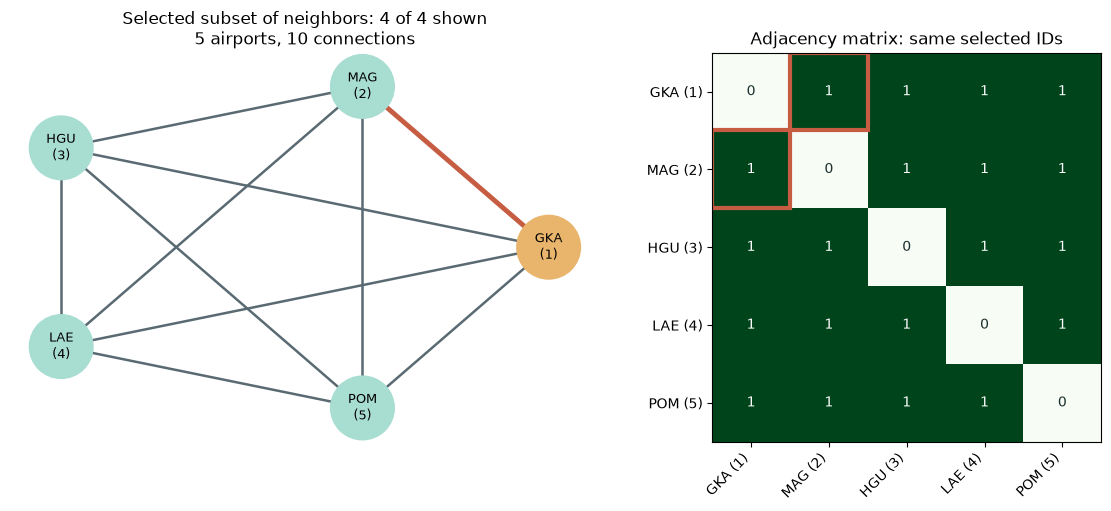

In [11]:
SELECTED_AIRPORT_ID = None

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
if not shared_graph:
    for axis in axes:
        axis.text(0.5, 0.5, 'No retained airports to display', ha='center', va='center', transform=axis.transAxes)
        axis.set_axis_off()
else:
    default_airport = selected_pair[0] if selected_pair else min(shared_graph.nodes)
    center = default_airport if SELECTED_AIRPORT_ID is None else SELECTED_AIRPORT_ID
    if center not in shared_graph:
        raise ValueError(f'Airport ID {center} is not in the shared graph.')
    ordered_nodes = [center, *sorted(shared_graph.neighbors(center))[:5]]
    local_graph = shared_graph.subgraph(ordered_nodes).copy()
    local_matrix = nx.to_numpy_array(local_graph, nodelist=ordered_nodes, dtype=int)
    labels = {}
    for airport_id in ordered_nodes:
        attributes = shared_graph.nodes[airport_id]
        code = attributes.get('iata') or attributes.get('icao') or 'ID'
        labels[airport_id] = f'{code}\n({airport_id})'
    positions = nx.circular_layout(local_graph)
    colors = ['#e9b46b' if airport_id == center else '#a8ddd1' for airport_id in ordered_nodes]
    nx.draw_networkx(local_graph, positions, ax=axes[0], nodelist=ordered_nodes, labels=labels,
                     node_color=colors, node_size=2100, font_size=9, edge_color='#596a72', width=1.8)
    axes[0].set_title(f'Selected subset of neighbors: {len(ordered_nodes)-1} of {shared_graph.degree(center)} shown\n{local_graph.number_of_nodes()} airports, {local_graph.number_of_edges()} connections')
    axes[0].set_axis_off()
    axes[1].imshow(local_matrix, cmap='Greens', vmin=0, vmax=1)
    matrix_labels = [labels[node].replace('\n', ' ') for node in ordered_nodes]
    axes[1].set_xticks(range(len(ordered_nodes)), matrix_labels, rotation=45, ha='right')
    axes[1].set_yticks(range(len(ordered_nodes)), matrix_labels)
    axes[1].set_title('Adjacency matrix: same selected IDs')
    for row in range(len(ordered_nodes)):
        for column in range(len(ordered_nodes)):
            value = local_matrix[row, column]
            axes[1].text(column, row, str(value), ha='center', va='center', color='white' if value else '#1d3030')
    if len(ordered_nodes) > 1:
        from matplotlib.patches import Rectangle
        highlighted = (center, ordered_nodes[1])
        nx.draw_networkx_edges(local_graph, positions, edgelist=[highlighted], ax=axes[0],
                               edge_color='#c65c42', width=3.5)
        for row, column in [(0, 1), (1, 0)]:
            axes[1].add_patch(Rectangle((column-.5, row-.5), 1, 1, fill=False,
                                        edgecolor='#c65c42', linewidth=3))
    assert (local_matrix == local_matrix.T).all() and not local_matrix.diagonal().any()
    print('Selected airport:', center, '| catalog record:', shared_graph.nodes[center])
    display(pd.DataFrame(local_matrix, index=matrix_labels, columns=matrix_labels))
plt.show()

### Offline interactive demonstration

The next cell generates [airport_network_demo.html](airport_network_demo.html) using `airport_demo.py` and its HTML template. Open the generated file directly in a browser; it needs no server or internet connection.

1. Select an airport by name, code and ID, choose a limit on displayed neighbors, and switch representations. 
2. The positions remain fixed across switches. 
3. The binary view uses a symmetric 0/1 adjacency matrix; the directional view uses a source-by-destination listing-count matrix. 
4. Parallel listings are grouped into labeled arrows for readability, with exact counts shown in the table. 
5. These are counts of distinct listings, not flights.

Demonstration:
- Press Goroka–Port Moresby example. 
- Switch to directional listings and count the four listings; switch back to see one connection. 
- Click the connection to highlight both binary matrix cells. 
- Select a different airport to inspect its selected subset of neighbors; click a node for details. 
- The limit does not describe the airport's total degree.


In [12]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
from src.airport_demo import export_airport_demo
from IPython.display import FileLink

demo_path = export_airport_demo(shared_graph, retained)
print('Offline demonstration generated. Open this HTML file in a browser:')
display(FileLink(str(demo_path)))

Offline demonstration generated. Open this HTML file in a browser:


/home/symmetry/repo/mdaie/project_graph/group-project/math-ai-project/notebooks/airport_network_demo.html

## 5. Reproducibility checks

The data may not contain every edge case, so this small synthetic fixture checks the rules independently: missing IDs, unmatched catalog IDs, unknown or nonzero stops, a self-loop, repeated and reverse records, a degree-one endpoint, and a code mismatch that remains eligible. 

It also checks that changing input order does not change the selected airport pairs or the optional listing counts. These fixture IDs and labels are illustrative, not claims about real airports.

In [13]:
fixture = pd.DataFrame([
    ('X', '10', 'WRONG', 1, 'BBB', 2, pd.NA, '0', 'JET'),
    ('X', '10', 'WRONG', 1, 'BBB', 2, pd.NA, '0', 'JET'),
    ('Y', '20', 'BBB', 2, 'AAA', 1, 'Y', '0', 'JET'),
    ('X', '10', 'BBB', 2, 'CCC', 3, pd.NA, '0', 'JET'),
    ('X', '10', 'AAA', pd.NA, 'BBB', 2, pd.NA, '0', 'JET'),
    ('X', '10', 'AAA', 1, 'XXX', 999, pd.NA, '0', 'JET'),
    ('X', '10', 'AAA', 1, 'CCC', 3, pd.NA, '1', 'JET'),
    ('X', '10', 'AAA', 1, 'CCC', 3, pd.NA, pd.NA, 'JET'),
    ('X', '10', 'AAA', 1, 'AAA', 1, pd.NA, '0', 'JET'),
], columns=ROUTE_FIELDS)
fixture['source_id'] = fixture['source_id'].astype('Int64')
fixture['destination_id'] = fixture['destination_id'].astype('Int64')
fixture['stop_count'] = pd.to_numeric(fixture['stops'], errors='coerce')
fixture_retained, fixture_exclusions = filter_route_records(fixture, {1, 2, 3})
assert fixture_exclusions == {'Missing or invalid endpoint ID': 1, 'Endpoint ID absent from catalog': 1,
                              'Nonzero or unknown stop count': 2, 'Same airport at both endpoints': 1}
assert len(fixture_retained) == 4 and fixture_retained['source_code'].eq('WRONG').sum() == 2
assert unordered_pairs(fixture_retained) == {(1, 2), (2, 3)}
assert count_distinct_listings(fixture_retained) == {(1, 2): 2, (2, 3): 1}
fixture_graph = nx.Graph(unordered_pairs(fixture_retained))
assert fixture_graph.degree[3] == 1 and nx.number_of_selfloops(fixture_graph) == 0
shuffled_fixture, shuffled_exclusions = filter_route_records(fixture.sample(frac=1, random_state=8), {1, 2, 3})
assert shuffled_exclusions == fixture_exclusions
assert unordered_pairs(shuffled_fixture) == unordered_pairs(fixture_retained)
assert count_distinct_listings(shuffled_fixture) == count_distinct_listings(fixture_retained)
print('Synthetic fixture: filtering, mismatch retention, loops, duplicates, reverse routes and row-order checks passed.')

Synthetic fixture: filtering, mismatch retention, loops, duplicates, reverse routes and row-order checks passed.


## 6. Findings for the team

The next cell produces a short narrative from the current input files. Its numbers come from the audit and construction above, not from copied results. 

- The source/destination mismatch counts are endpoint diagnostics, so they can refer to the same route record. 

- The sequential exclusion counts are mutually exclusive. The one-direction-only statistic describes this dataset snapshot; it does not establish that return service is unavailable.

- The recommended deliverable is the in-memory `shared_graph`: an unweighted NetworkX graph with integer OpenFlights ID nodes and catalog labels. `retained` contains the qualifying route records; `listing_graph_optional` is a separate copy with a named record-count attribute. 

- Use a copy for experiments that remove vertices. Separate notebooks do not automatically share variables. 

- Section 8 provides the implemented CSV/manifest handoff in `data/derived/airport_network_v1` and the shared loader `src.airport_graph.load_shared_graph`.

In [14]:
print(f'Input: {len(routes):,} route records and {len(catalog):,} catalog airports.')
print(f'Filtering excluded {sum(exclusions.values()):,} records; {len(retained):,} records remain.')
print(f'\nThe binary graph contains {shared_graph.number_of_nodes():,} airports and {shared_graph.number_of_edges():,} connections.')
print(f'{len(reciprocal_edges):,} unordered pairs have retained listings in both directions; '
      f'{len(one_direction_edges):,} are listed in only one direction in this snapshot.')
print('\nCode/ID mismatch diagnostics:',
      f"source={endpoint_diagnostics['source']['Code differs from both catalog codes']:,},",
      f"destination={endpoint_diagnostics['destination']['Code differs from both catalog codes']:,}; these counts can overlap.")
if selected_pair is not None:
    print(f'The illustrated pair {selected_pair} has {len(pair_listings)} distinct normalized listings but one binary edge.')
print('\nRecommendation: use the binary graph for structural connectivity; do not call listing counts flight frequency.')

Input: 67,663 route records and 7,698 catalog airports.
Filtering excluded 904 records; 66,759 records remain.

The binary graph contains 3,214 airports and 18,858 connections.
18,048 unordered pairs have retained listings in both directions; 810 are listed in only one direction in this snapshot.

Code/ID mismatch diagnostics: source=538, destination=543; these counts can overlap.
The illustrated pair (1, 5) has 4 distinct normalized listings but one binary edge.

Recommendation: use the binary graph for structural connectivity; do not call listing counts flight frequency.


## 7. Presentation flow

Refer to slides and the actual pair comparison or adjacency figure as a visual demonstration.

### Questions

- **Why IDs instead of codes?** 
    - The catalog's unique IDs are used as keys; IATA/ICAO codes are labels and can be missing or inconsistent.
- **Is an edge a two-way flight?** 
    - No. It means at least one retained direction was listed; direction is discarded in this undirected model.
- **Why remove self-loops and nonzero-stop records?** 
    -  The chosen model is a loop-free simple graph of zero-intermediate-stop listings. Exclusions and their effect are reported; another research question may require different rules.
- **Why keep codeshares?** 
    - The binary model asks whether a listing exists, not which airline operated it. Codeshares can inflate optional record counts, so the count is not flight frequency.
- **Why retain mismatched codes?** 
    - The matching ID is the chosen key; disagreements are visible for review. Incorrect IDs remain a data-quality risk, and resolving them would require an explicit, independently justified policy.
- **Can we use this graph to plan actual journeys?** 
    - Not by itself. It has no schedules, travel times, capacities, transfer constraints, or assurance that the snapshot is current.

Identifier audit, graph construction, the record-to-edge example, the weight decision and the section delivered.

### A simpler audience-facing sequence

Use the real Goroka–Port Moresby pair as the recurring example, with the audit and weight details available for questions.

| Time | Demonstration and message |
|---|---|
| 0:00–0:45 | Identify the two airports by name, code and ID. Ask how many connections four listings represent. |
| 0:45–1:25 | Switch from directional listings to the binary graph: four listings become one connection; this does not assert two-way service. |
| 1:25–2:10 | Show the filtering-to-connections figure and one audit decision. Distinguish exclusions from collapsing valid listings. |
| 2:10–2:45 | Explain the weight counterexample and recommend one edge = one hop for the shared model. |
| 2:45–3:40 | Select an airport, highlight an edge and its matrix cells, explain the selected subset, and point teammates to the shared export. |

Before presenting, restart the kernel and run all cells in order. Open the generated HTML in a browser and rehearse the example; keep the static figures as a fallback.

## APPENDIX: Exported files and shared loader

## 8. Shared handoff for the team

This section exports the graph defined above without changing the original OpenFlights files. It produces:

- A node table keyed by OpenFlights airport ID, with labels and numeric latitude/longitude; a deduplicated edge table contains one ascending-ID pair per undirected connection.
- The retained route records, preserving source and destination order, airline, codeshare, stops and equipment. These rows remain listings, not flight-frequency measurements.
- A JSON manifest containing graph rules, ordered exclusion counts, diagnostic counts, schemas, library versions, input hashes and output checksums.

The companion `airport_graph.py` provides `build_graph_from_tables(nodes, edges)` and `load_shared_graph(directory)`. 
- The loader checks table schemas, IDs, canonical unique edges, checksums and graph size. Coordinates outside geographic ranges or unavailable in the catalog are exported as missing, not used to remove airports. 
- Code/ID discrepancies remain flagged in the audit and are not automatically corrected.

The export directory is `data/derived/airport_network_v1`. 
- Re-running with identical content reuses it; if an existing bundle differs or is incomplete, the notebook stops instead of overwriting it. 
- Choose a new directory for a different version. The raw `data/routes.dat` and `data/airports.dat` remain unchanged.

In [15]:
from src.airport_graph import build_graph_from_tables, load_shared_graph

node_fields = ['name', 'city', 'country', 'iata', 'icao', 'latitude', 'longitude']
node_table = catalog.loc[sorted(shared_graph.nodes), node_fields].reset_index().copy()
coordinate_issues = {}
for coordinate, minimum, maximum in [('latitude', -90, 90), ('longitude', -180, 180)]:
    numeric = pd.to_numeric(node_table[coordinate], errors='coerce')
    valid = numeric.between(minimum, maximum).fillna(False)
    coordinate_issues[f'{coordinate}_missing_or_invalid'] = int((~valid).sum())
    node_table[coordinate] = numeric.where(valid, pd.NA)
edge_table = pd.DataFrame(sorted(edge_pairs), columns=['source_id', 'destination_id'])
filtered_routes = retained[ROUTE_FIELDS].copy()

rebuilt_in_memory = build_graph_from_tables(node_table, edge_table)
assert set(rebuilt_in_memory.nodes) == set(shared_graph.nodes)
assert {tuple(sorted(edge)) for edge in rebuilt_in_memory.edges} == edge_pairs
for airport_id, attributes in shared_graph.nodes(data=True):
    assert all(rebuilt_in_memory.nodes[airport_id][field] == attributes[field]
               for field in ['name', 'city', 'country', 'iata', 'icao'])
assert len(filtered_routes) == len(retained)
print(f'Prepared {len(node_table):,} nodes, {len(edge_table):,} edges, and {len(filtered_routes):,} retained route records.')
print('Coordinate issues in graph nodes:', coordinate_issues)
display(node_table.head(10))
display(edge_table.head(10))

Prepared 3,214 nodes, 18,858 edges, and 66,759 retained route records.
Coordinate issues in graph nodes: {'latitude_missing_or_invalid': 0, 'longitude_missing_or_invalid': 0}


,airport_id,name,city,country,iata,icao,latitude,longitude
0,1,Goroka Airport,Goroka,Papua New Guinea,GKA,AYGA,-6.08169,145.391998
1,2,Madang Airport,Madang,Papua New Guinea,MAG,AYMD,-5.20708,145.789001
2,3,Mount Hagen Kagamuga Airport,Mount Hagen,Papua New Guinea,HGU,AYMH,-5.82679,144.296005
3,4,Nadzab Airport,Nadzab,Papua New Guinea,LAE,AYNZ,-6.569803,146.725977
4,5,Port Moresby Jacksons International Airport,Port Moresby,Papua New Guinea,POM,AYPY,-9.44338,147.220001
5,6,Wewak International Airport,Wewak,Papua New Guinea,WWK,AYWK,-3.58383,143.669006
6,7,Narsarsuaq Airport,Narssarssuaq,Greenland,UAK,BGBW,61.1605,-45.425999
7,8,Godthaab / Nuuk Airport,Godthaab,Greenland,GOH,BGGH,64.190903,-51.678101
8,9,Kangerlussuaq Airport,Sondrestrom,Greenland,SFJ,BGSF,67.012222,-50.711603
9,10,Thule Air Base,Thule,Greenland,THU,BGTL,76.531197,-68.703201


,source_id,destination_id
0,1,2
1,1,3
2,1,4
3,1,5
4,2,3
5,2,4
6,2,5
7,2,6
8,2,5430
9,2,5436


In [16]:
import hashlib
import json
import sys
import tempfile
import math

EXPORT_DIR = DATA_DIR / 'derived' / 'airport_network_v1'

def sha256_bytes(contents):
    return hashlib.sha256(contents).hexdigest()

source_hashes = {}
for filename, fields, loaded in [('routes.dat', ROUTE_FIELDS, routes_raw),
                                 ('airports.dat', AIRPORT_FIELDS, airports_raw)]:
    source_path = DATA_DIR / filename
    first_hash = sha256_bytes(source_path.read_bytes())
    reloaded = pd.read_csv(source_path, header=None, names=fields, dtype='string', keep_default_na=False)
    if not reloaded.equals(loaded) or sha256_bytes(source_path.read_bytes()) != first_hash:
        raise RuntimeError(f'{filename} changed during analysis; rerun the notebook before exporting.')
    source_hashes[f'data/{filename}'] = first_hash

file_tables = {
    'nodes': ('airport_nodes.csv', node_table),
    'edges': ('airport_edges.csv', edge_table),
    'filtered_routes': ('filtered_routes.csv', filtered_routes),
}
file_bytes = {filename: table.to_csv(index=False, na_rep='', lineterminator='\n').encode('utf-8')
              for filename, table in file_tables.values()}
manifest = {
    'format_version': 1,
    'model': {
        'node_key': 'integer OpenFlights airport ID',
        'nodes': 'catalog-matched endpoints of retained route records',
        'edge_rule': 'one unordered pair if any retained zero-stop route is listed in either direction',
        'graph_type': 'undirected simple graph',
        'edge_weights': 'none',
        'filter_order': list(exclusions),
        'exclusion_policy': 'first failed filter per record',
        'codeshares': 'included',
        'code_id_mismatches': 'reported but not automatically remapped or excluded',
        'degree_one_nodes': 'retained',
        'missing_values': 'empty CSV field after normalization',
        'coordinates': 'numeric degrees; missing or out-of-range values are blank',
        'snapshot_date': None,
    },
    'counts': {
        'input_route_records': len(routes),
        'retained_route_records': len(filtered_routes),
        'excluded_route_records': sum(exclusions.values()),
        'graph_nodes': len(node_table),
        'graph_edges': len(edge_table),
        'exclusions_by_first_failed_check': exclusions,
        'coordinate_issues_in_graph_nodes': coordinate_issues,
    },
    'overlapping_endpoint_diagnostics': endpoint_diagnostics,
    'other_quality_diagnostics': quality_summary,
    'source_sha256': source_hashes,
    'files': {name: {'path': filename, 'sha256': sha256_bytes(file_bytes[filename]),
                     'columns': list(table.columns)}
              for name, (filename, table) in file_tables.items()},
    'versions': {'python': sys.version.split()[0], 'pandas': pd.__version__, 'networkx': nx.__version__},
    'data_source': 'https://openflights.org/data.php',
}
file_bytes['manifest.json'] = (json.dumps(manifest, indent=2, sort_keys=True, ensure_ascii=False) + '\n').encode('utf-8')

if EXPORT_DIR.exists():
    if not EXPORT_DIR.is_dir() or any(not (EXPORT_DIR / filename).is_file() or
                                      (EXPORT_DIR / filename).read_bytes() != contents
                                      for filename, contents in file_bytes.items()):
        raise FileExistsError(f'{EXPORT_DIR} already contains different or incomplete data; choose a new EXPORT_DIR.')
    print(f'Existing identical handoff reused: {EXPORT_DIR}')
else:
    EXPORT_DIR.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.TemporaryDirectory(prefix='.airport-network-', dir=EXPORT_DIR.parent) as temporary_directory:
        staging = Path(temporary_directory) / 'bundle'
        staging.mkdir()
        for filename, contents in file_bytes.items():
            with (staging / filename).open('xb') as output_file:
                output_file.write(contents)
        staging.rename(EXPORT_DIR)
    print(f'Created handoff: {EXPORT_DIR}')
for filename in file_bytes:
    print(' ', EXPORT_DIR / filename)

Created handoff: ../data/derived/airport_network_v1
  ../data/derived/airport_network_v1/airport_nodes.csv
  ../data/derived/airport_network_v1/airport_edges.csv
  ../data/derived/airport_network_v1/filtered_routes.csv
  ../data/derived/airport_network_v1/manifest.json


In [17]:
loaded_graph = load_shared_graph(EXPORT_DIR)
loaded_routes = pd.read_csv(EXPORT_DIR / manifest['files']['filtered_routes']['path'],
                            dtype='string', keep_default_na=False)
expected_routes = filtered_routes.astype('string').fillna('').reset_index(drop=True)
pd.testing.assert_frame_equal(loaded_routes, expected_routes)
assert sha256_bytes((EXPORT_DIR / manifest['files']['filtered_routes']['path']).read_bytes()) == manifest['files']['filtered_routes']['sha256']
assert set(loaded_graph.nodes) == set(shared_graph.nodes)
assert {tuple(sorted(edge)) for edge in loaded_graph.edges} == edge_pairs
assert not loaded_graph.is_directed() and nx.number_of_selfloops(loaded_graph) == 0
assert all('weight' not in attributes for _, _, attributes in loaded_graph.edges(data=True))
for airport_id, attributes in shared_graph.nodes(data=True):
    assert all(loaded_graph.nodes[airport_id][field] == attributes[field]
               for field in ['name', 'city', 'country', 'iata', 'icao'])
for record in node_table.itertuples(index=False):
    for coordinate in ['latitude', 'longitude']:
        expected = getattr(record, coordinate)
        actual = loaded_graph.nodes[int(record.airport_id)][coordinate]
        if pd.isna(expected):
            assert actual is None
        else:
            assert math.isclose(float(expected), actual, rel_tol=1e-12, abs_tol=1e-12)
assert manifest['counts']['input_route_records'] == sum(exclusions.values()) + len(loaded_routes)
print(f'Reloaded graph: {loaded_graph.number_of_nodes():,} airports and {loaded_graph.number_of_edges():,} edges.')
print(f'Validated {len(loaded_routes):,} directional route records, graph labels, coordinates and checksums.')

Reloaded graph: 3,214 airports and 18,858 edges.
Validated 66,759 directional route records, graph labels, coordinates and checksums.


### How to load the handoff

Keep `airport_graph.py` and the exported directory together with the project. From another notebook started in the project directory:


In [18]:
from pathlib import Path
from src.airport_graph import load_shared_graph

bundle = Path('../data/derived/airport_network_v1')
graph = load_shared_graph(bundle)
print(graph.number_of_nodes(), graph.number_of_edges())
print(graph.nodes[1])  # airport IDs are integers; coordinates are floats or None

3214 18858
{'name': 'Goroka Airport', 'city': 'Goroka', 'country': 'Papua New Guinea', 'iata': 'GKA', 'icao': 'AYGA', 'latitude': -6.081689834590001, 'longitude': 145.391998291}


`load_shared_graph` verifies the node and edge table checksums and graph size against the manifest. 
- To work with the tables directly, use `pd.read_csv(..., dtype='string', keep_default_na=False)`, then pass the node and edge DataFrames to `build_graph_from_tables(nodes, edges)`. 
- Keeping default NA parsing disabled preserves legitimate codes such as `NA`; an empty CSV field represents a missing value.

For airline, codeshare or directional analysis, read `filtered_routes.csv` from the same directory with `pd.read_csv(bundle / 'filtered_routes.csv', dtype='string', keep_default_na=False)`. Its `source_id` and `destination_id` columns are strings on import; convert them to integers to compare them with graph node IDs.
- This file retains directional records and possible duplicates, whereas `airport_edges.csv` is deduplicated and undirected.
- Its checksum and schema are documented in the manifest and checked by the round-trip cell above.

The manifest records the filter order, exclusions, diagnostics, input and output checksums and package versions.
- Mismatched codes were **flagged, not resolved**; these artifacts are a reproducible model, not a guarantee of current or error-free flight data. 
- The graph is binary and unweighted, so do not interpret an edge as a flight count or assume a reverse listing. 
- Participants should document any additional preprocessing on a copy of the loaded graph.